In [23]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme("whitegrid")

ValueError: context must be in paper, notebook, talk, poster

# 5 - $F_1(α)$
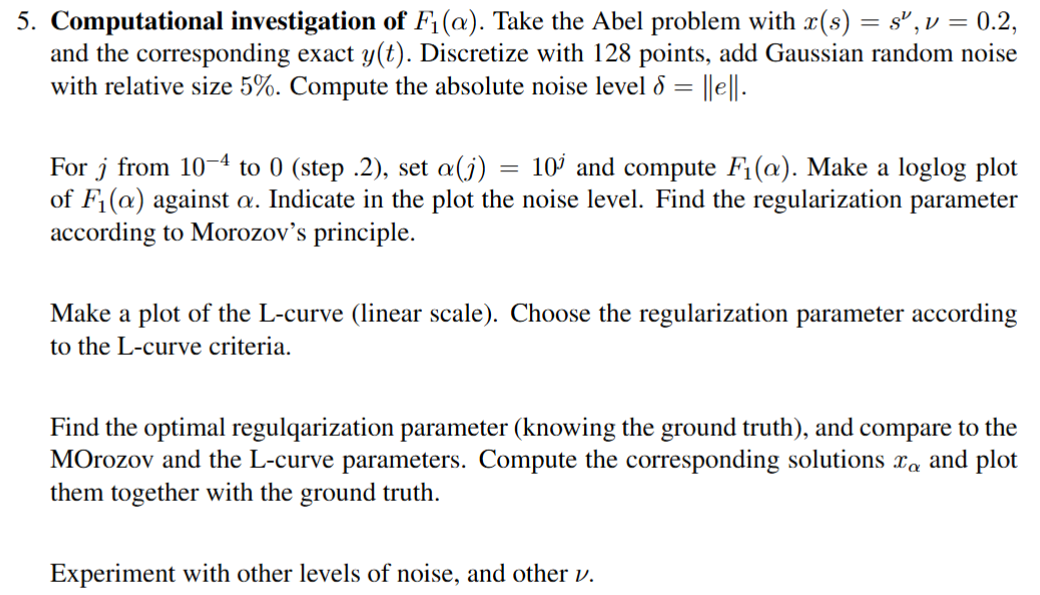

0.23560050213015998
Noise level (delta): 2.3560e-01
(21, 7)
(21,)
[-2.46857903e-04 -4.50866676e-04 -1.67346736e-03 -2.57267844e-03
 -3.89170921e-03 -5.74929439e-03 -8.21092912e-03 -1.11875338e-02
 -1.43154972e-02 -1.69870785e-02 -1.88972189e-02 -2.10054468e-02
 -2.54360324e-02 -3.42401297e-02 -4.94928291e-02 -7.43887960e-02
 -1.14169211e-01 -1.77649463e-01 -2.80369850e-01 -4.39196350e-01
 -4.73671059e-01]
0
2
Optimal alpha (minimizing ||x - x_α||): 2.5119e-02
L-curve alpha (maximum curvature): 2.5119e-04
Discrepancy principle alpha: 2.5119e-02
[ 8.28520376 11.51557882 16.53701706 16.47828019 16.36978182 16.16463719
 15.77452659 15.049383   13.78337502 11.80862662  9.19419454  6.3624401
  3.89430427  2.16257237  1.15752105  0.64479344  0.39671733  0.27488878
  0.21061021  0.13768006  0.08450638]


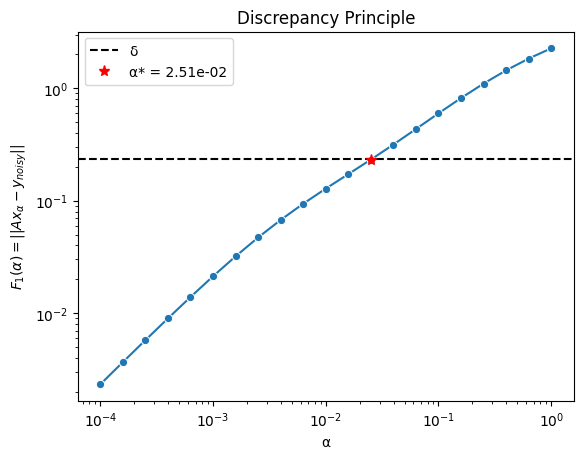

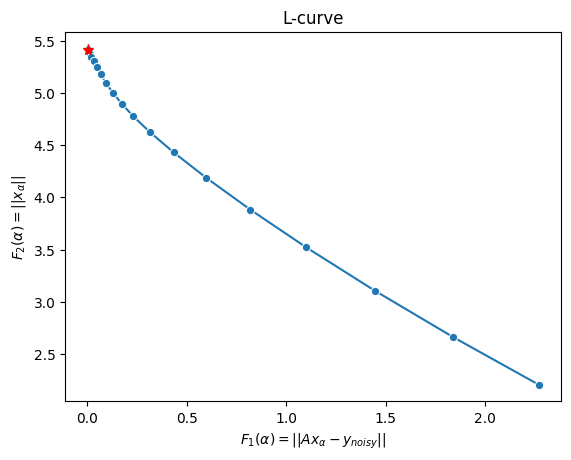

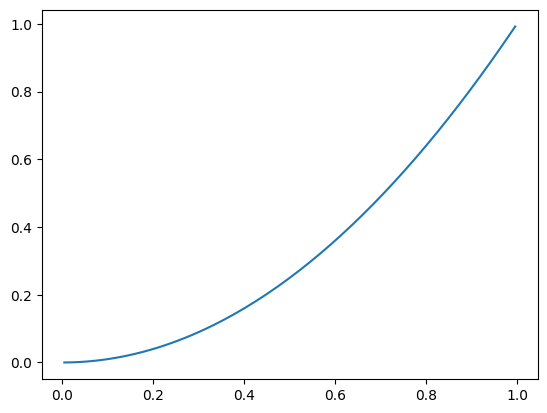

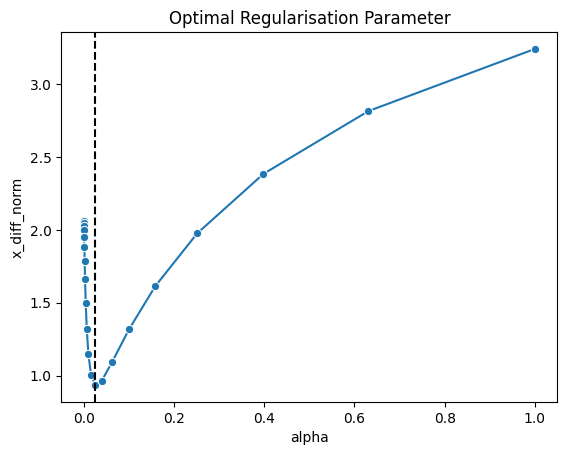

In [ ]:
n = 128
noise_level = 0.05

nu = 0.2
def x_func(s):
    return s**nu

a = 0
b = 1
h = (b - a) / n
s = (a + (np.arange(n) + 0.5) * h)
t = s + h/2  # Shift t values to prevent singularity at t=s

s_mesh, t_mesh = np.meshgrid(s, t)

# Create A matrix
A = np.zeros((n, n))
indices = s_mesh < t_mesh  # Select according to integral
A[indices] = h / np.sqrt((t_mesh[indices] - s_mesh[indices]))

# Set up x
def x_1_func(s):
    return s**2

x_true = x_1_func(s)
y_true = A @ x_true

# Add noise
unscaled_noise = np.random.randn(*y_true.shape)
unscaled_noise_level = np.linalg.norm(unscaled_noise)
noise_coeff = noise_level * np.linalg.norm(y_true) / unscaled_noise_level
noise = noise_coeff * unscaled_noise
y_noisy = y_true + noise

delta = np.linalg.norm(noise)
print(f"Noise level (delta): {delta:.4e}")

def F_1(alpha):
    x_alpha = np.linalg.inv(A.T @ A + alpha * np.eye(n)) @ A.T @ y_noisy
    return np.linalg.norm(A @ x_alpha - y_noisy)

def F_2(alpha):
    x_alpha = np.linalg.inv(A.T @ A + alpha * np.eye(n)) @ A.T @ y_noisy
    return np.linalg.norm(x_alpha)

data = []
# Note: Mistake in handout
js = np.arange(-4, 0 + 0.2, 0.2, dtype=np.float64)
for j in js:
    alpha = 10**j
    x_alpha = np.linalg.inv(A.T @ A + alpha * np.eye(n)) @ A.T @ y_noisy
    F_1_val = F_1(alpha)
    F_2_val = F_2(alpha)

    x_diff = x_true - x_alpha

    data.append({
        "j": j,
        "alpha": alpha,
        "F_1": F_1_val,
        "F_2": F_2_val,
        "x_alpha": x_alpha,
        "x_diff": x_diff,
        "x_diff_norm": np.linalg.norm(x_diff),
    })

df = pd.DataFrame(data)

### Find optimal point and its estimates
# True Optimal
alpha_optimal_idx = np.argmin(df["x_diff_norm"])
alpha_optimal = df.loc[alpha_optimal_idx, "alpha"]
# Discrepancy
alpha_discrepancy_idx = np.argmin(np.abs(df['F_1'] - delta))
alpha_discrepancy = df.iloc[alpha_discrepancy_idx]['alpha']
# L-curve corner (maximum curvature)
F_1_hat = 2 * np.log(df["F_1"])
F_2_hat = 2 * np.log(df["F_2"])
dF1 = np.gradient(F_1_hat, df["alpha"])
dF2 = np.gradient(F_2_hat, df["alpha"])
ddF1 = np.gradient(dF1, df["alpha"])
ddF2 = np.gradient(dF2, df["alpha"])
curvatures = 2 * (
    (dF1 * ddF2 - dF2 * ddF1)
    / (dF1 ** 2 + dF1 ** 2)**(3/2)
)
print(df.shape)
print(curvatures.shape)
print(curvatures)
alpha_L_curve_idx = np.argmax(curvatures)
print(alpha_L_curve_idx)
alpha_L_curve = df.iloc[alpha_L_curve_idx]["alpha"]
F_1_L_curve = F_1(alpha_L_curve)
F_2_L_curve = F_2(alpha_L_curve)

# I can't seem to get the above formula to work, just take gradients
curvatures = np.gradient(np.gradient(df["F_2"], df["F_1"]), df["F_1"])
alpha_L_curve_idx = np.argmax(curvatures)
alpha_L_curve = df.iloc[alpha_L_curve_idx]["alpha"]
F_1_L_curve = F_1(alpha_L_curve)
F_2_L_curve = F_2(alpha_L_curve)
print(alpha_L_curve_idx)
# TODO: This still seems a bit wonky


# Print
print(f"Optimal alpha (minimizing ||x - x_α||): {alpha_optimal:.4e}")
print(f"L-curve alpha (maximum curvature): {alpha_L_curve:.4e}")
print(f"Discrepancy principle alpha: {alpha_discrepancy:.4e}")

sns.lineplot(data=df, x="alpha", y="F_1", marker="o")
plt.axhline(y=delta, label="δ", color="black", linestyle="--")

# Plot intersection point
F_1_alpha_discrepancy = F_1(alpha_discrepancy)
plt.plot(alpha_discrepancy, F_1_alpha_discrepancy, "r*", ms=8, label=f"α* = {alpha_discrepancy:.2e}")
plt.title("Discrepancy Principle")
plt.xlabel("α")
plt.ylabel("$F_1(α) = ||A x_α - y_{noisy}||$")
plt.loglog()
plt.legend()

plt.figure()
sns.lineplot(data=df, x="F_1", y="F_2", marker="o")
# plt.loglog()
plt.title("L-curve")
plt.xlabel("$F_1(α) = ||A x_α - y_{noisy}||$")
plt.ylabel("$F_2(α) = ||x_α||$")
plt.plot(F_1_L_curve, F_2_L_curve, "r*", ms=8, label=f"α_L = {alpha_L_curve:.2e}")

plt.figure()
plt.plot(s, x_true, label="True x")

plt.figure()
plt.title("Optimal Regularisation Parameter")
sns.lineplot(data=df, x="alpha", y="x_diff_norm", marker="o")
plt.axvline(x=alpha_optimal, label="Optimal α", color="black", linestyle="--")

print(np.gradient(np.gradient(df["F_2"], df["F_1"]), df["F_1"]))